In [148]:
!pip install pandas numpy scikit-learn matplotlib seaborn shap gradio google-genai

In [149]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [150]:
import os

folder_path = "/content/drive/MyDrive/FinShield_Data"

print(os.listdir(folder_path))

['paysim dataset.csv']


In [151]:
import pandas as pd

file_path = folder_path + "/paysim dataset.csv"

df = pd.read_csv(file_path, nrows=100000)

print("FinShield AI Dataset loaded!")

print("Number of transactions:", len(df))

df.head()

FinShield AI Dataset loaded!
Number of transactions: 100000


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [152]:
# Check transaction types

print("Transaction types:")

print(df["type"].value_counts())

# Check fraud distribution

print("\nFraud distribution:")

print(df["isFraud"].value_counts())

Transaction types:
type
PAYMENT     39512
CASH_OUT    30718
CASH_IN     20185
TRANSFER     8597
DEBIT         988
Name: count, dtype: int64

Fraud distribution:
isFraud
0    99884
1      116
Name: count, dtype: int64


In [153]:
# Remove unnecessary columns

df = df.drop(columns=["nameOrig", "nameDest", "isFlaggedFraud"])

print("Columns after cleaning:")

print(df.columns)

Columns after cleaning:
Index(['step', 'type', 'amount', 'oldbalanceOrg', 'newbalanceOrig',
       'oldbalanceDest', 'newbalanceDest', 'isFraud'],
      dtype='object')


In [154]:
# Convert transaction types into numerical values

df = pd.get_dummies(df, columns=["type"], dtype=int)

print("Updated dataset:")

print(df.head())

print("\nNew columns:")

print(df.columns)

Updated dataset:
   step    amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  \
0     1   9839.64       170136.0       160296.36             0.0   
1     1   1864.28        21249.0        19384.72             0.0   
2     1    181.00          181.0            0.00             0.0   
3     1    181.00          181.0            0.00         21182.0   
4     1  11668.14        41554.0        29885.86             0.0   

   newbalanceDest  isFraud  type_CASH_IN  type_CASH_OUT  type_DEBIT  \
0             0.0        0             0              0           0   
1             0.0        0             0              0           0   
2             0.0        1             0              0           0   
3             0.0        1             0              1           0   
4             0.0        0             0              0           0   

   type_PAYMENT  type_TRANSFER  
0             1              0  
1             1              0  
2             0              1  
3             0

In [155]:
# Separate features and target

X = df.drop("isFraud", axis=1)

y = df["isFraud"]

print("Features shape:", X.shape)

print("Target shape:", y.shape)

print("\nTarget distribution:")

print(y.value_counts())

Features shape: (100000, 11)
Target shape: (100000,)

Target distribution:
isFraud
0    99884
1      116
Name: count, dtype: int64


In [156]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.2,

    random_state=42,

    stratify=y

)

print("Training data:", X_train.shape)

print("Testing data:", X_test.shape)

print("\nFraud cases in training data:")

print(y_train.value_counts())

print("\nFraud cases in testing data:")

print(y_test.value_counts())

Training data: (80000, 11)
Testing data: (20000, 11)

Fraud cases in training data:
isFraud
0    79907
1       93
Name: count, dtype: int64

Fraud cases in testing data:
isFraud
0    19977
1       23
Name: count, dtype: int64


In [157]:
from sklearn.ensemble import RandomForestClassifier

# Create the model

model = RandomForestClassifier(

    n_estimators=100,

    random_state=42,

    class_weight="balanced",

    n_jobs=-1

)

# Train the model

model.fit(X_train, y_train)

print("FinShield AI model trained successfully!")

FinShield AI model trained successfully!


In [158]:
from sklearn.metrics import classification_report, confusion_matrix

# Make predictions

y_pred = model.predict(X_test)

# Evaluate the model

print("FINSHIELD AI — MODEL EVALUATION")

print(classification_report(y_test, y_pred))

# Show confusion matrix

print("Confusion Matrix:")

print(confusion_matrix(y_test, y_pred))

FINSHIELD AI — MODEL EVALUATION
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     19977
           1       0.90      0.39      0.55        23

    accuracy                           1.00     20000
   macro avg       0.95      0.70      0.77     20000
weighted avg       1.00      1.00      1.00     20000

Confusion Matrix:
[[19976     1]
 [   14     9]]


In [159]:
import pandas as pd

# Get feature importance

importance = pd.DataFrame({

    "Feature": X_train.columns,

    "Importance": model.feature_importances_

})

# Sort features by importance

importance = importance.sort_values(

    by="Importance",

    ascending=False

)

print("Most important transaction features:")

print(importance.head(10))

Most important transaction features:
           Feature  Importance
3   newbalanceOrig    0.180293
2    oldbalanceOrg    0.172106
0             step    0.137248
4   oldbalanceDest    0.115576
9     type_PAYMENT    0.094495
5   newbalanceDest    0.085596
1           amount    0.083205
10   type_TRANSFER    0.076030
7    type_CASH_OUT    0.035590
6     type_CASH_IN    0.019324


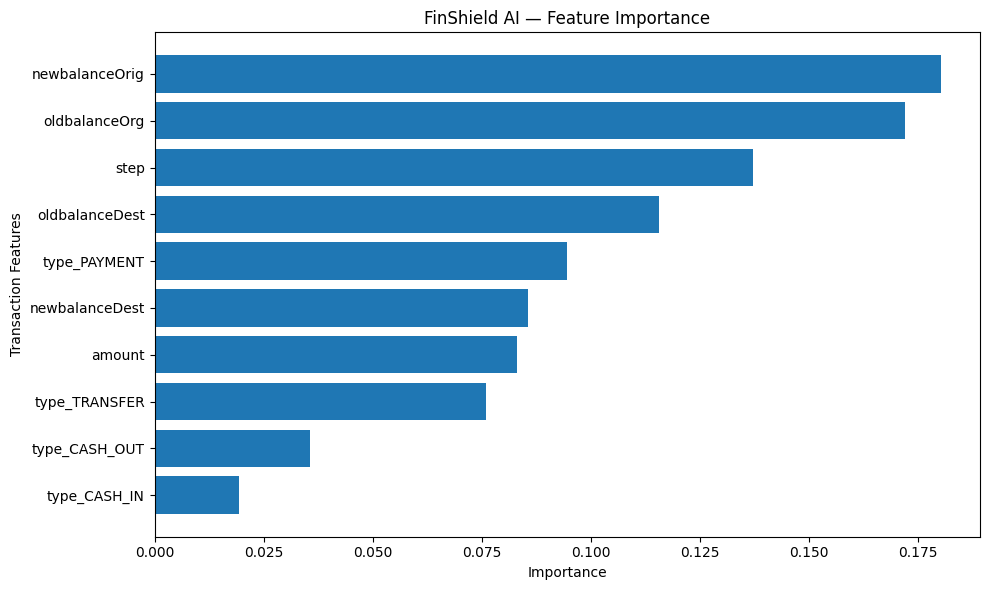

In [160]:
import matplotlib.pyplot as plt

# Select top 10 features

top_features = importance.head(10)

# Create a bar chart

plt.figure(figsize=(10, 6))

plt.barh(

    top_features["Feature"],

    top_features["Importance"]

)

plt.xlabel("Importance")

plt.ylabel("Transaction Features")

plt.title("FinShield AI — Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()

plt.show()

In [161]:
# Select one transaction from test data

transaction = X_test.iloc[[0]]

# Make prediction

prediction = model.predict(transaction)[0]

# Get fraud risk score

risk_score = model.predict_proba(transaction)[0][1] * 100

# Display result

print("FINSHIELD AI — TRANSACTION ANALYSIS")

print("-----------------------------------")

if prediction == 1:

    print("Result: Suspicious transaction")

else:

    print("Result: Normal transaction")

print(f"Fraud risk score: {risk_score:.2f}%")

FINSHIELD AI — TRANSACTION ANALYSIS
-----------------------------------
Result: Normal transaction
Fraud risk score: 0.00%


WHY DID FINSHIELD AI MAKE THIS PREDICTION?
          Feature  Contribution
2   oldbalanceOrg     -0.191141
9    type_PAYMENT     -0.135540
10  type_TRANSFER     -0.068530
0            step     -0.058508
7   type_CASH_OUT     -0.037281


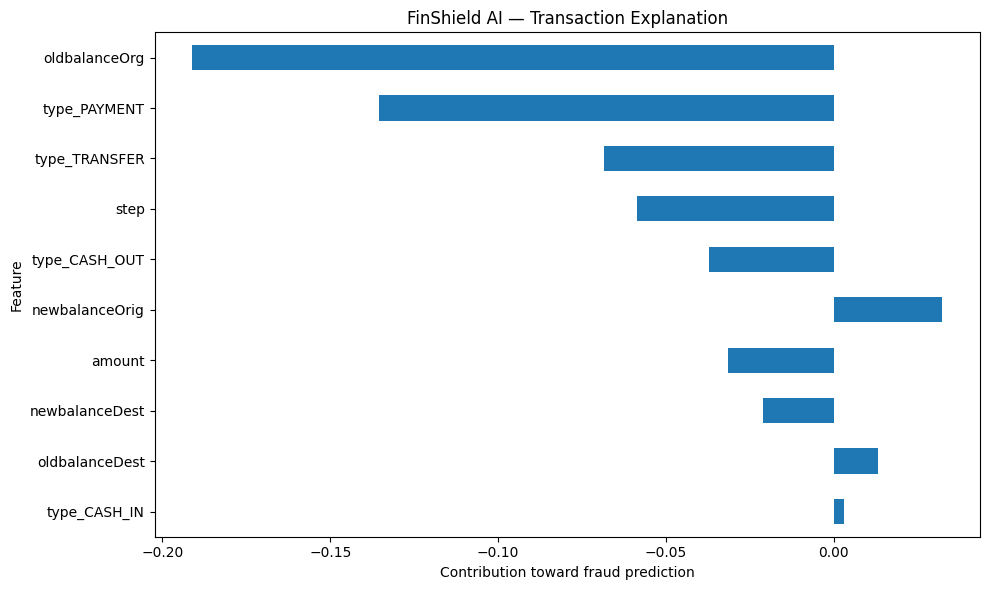

In [162]:
import shap

import pandas as pd

import matplotlib.pyplot as plt

# Create SHAP explainer

explainer = shap.TreeExplainer(model)

# Explain our selected transaction

shap_values = explainer.shap_values(transaction)

# Get contributions toward the fraud class

if isinstance(shap_values, list):

    fraud_contributions = shap_values[1][0]

elif len(shap_values.shape) == 3:

    fraud_contributions = shap_values[0, :, 1]

else:

    fraud_contributions = shap_values[0]

# Create explanation table

explanation = pd.DataFrame({

    "Feature": transaction.columns,

    "Contribution": fraud_contributions

})

# Sort by contribution strength

explanation["Abs_Contribution"] = (

    explanation["Contribution"].abs()

)

explanation = explanation.sort_values(

    by="Abs_Contribution",

    ascending=False

)

print("WHY DID FINSHIELD AI MAKE THIS PREDICTION?")

print(explanation.head(5)[["Feature", "Contribution"]])

# Visualize explanation

explanation.head(10).plot(

    x="Feature",

    y="Contribution",

    kind="barh",

    legend=False,

    figsize=(10, 6)

)

plt.title("FinShield AI — Transaction Explanation")

plt.xlabel("Contribution toward fraud prediction")

plt.gca().invert_yaxis()

plt.tight_layout()

plt.show()

In [163]:
def analyze_transaction(

    step,

    transaction_type,

    amount,

    oldbalanceOrg,

    newbalanceOrig,

    oldbalanceDest,

    newbalanceDest

):

    transaction_data = pd.DataFrame(

        0,

        index=[0],

        columns=X_train.columns

    )

    transaction_data["step"] = step

    transaction_data["amount"] = amount

    transaction_data["oldbalanceOrg"] = oldbalanceOrg

    transaction_data["newbalanceOrig"] = newbalanceOrig

    transaction_data["oldbalanceDest"] = oldbalanceDest

    transaction_data["newbalanceDest"] = newbalanceDest

    type_column = "type_" + transaction_type

    if type_column not in transaction_data.columns:

        print("Invalid transaction type!")

        return

    transaction_data[type_column] = 1

    prediction = model.predict(transaction_data)[0]

    score = model.predict_proba(transaction_data)[0][1] * 100

    # Assign a demonstration risk level

    if score < 30:

        risk_level = "LOW"

    elif score < 70:

        risk_level = "MEDIUM"

    else:

        risk_level = "HIGH"

    print("FINSHIELD AI — TRANSACTION REPORT")

    print("-----------------------------------")

    print(f"Prediction: {'Suspicious' if prediction == 1 else 'Normal'}")

    print(f"Model score: {score:.2f}%")

    print(f"Risk level: {risk_level}")

    if risk_level == "LOW":

        print("Recommendation: No strong warning from the model.")

    elif risk_level == "MEDIUM":

        print("Recommendation: Additional verification is recommended.")

    else:

        print("Recommendation: Further investigation is recommended.")

In [164]:
analyze_transaction(

    step=100,

    transaction_type="TRANSFER",

    amount=500000,

    oldbalanceOrg=600000,

    newbalanceOrig=100000,

    oldbalanceDest=200000,

    newbalanceDest=700000

)

FINSHIELD AI — TRANSACTION REPORT
-----------------------------------
Prediction: Normal
Model score: 0.00%
Risk level: LOW
Recommendation: No strong warning from the model.


In [165]:
import gradio as gr

import pandas as pd

def analyze_for_interface(

    step,

    transaction_type,

    amount,

    oldbalanceOrg,

    newbalanceOrig,

    oldbalanceDest,

    newbalanceDest

):

    # Prepare transaction data

    transaction_data = pd.DataFrame(

        0,

        index=[0],

        columns=X_train.columns

    )

    transaction_data["step"] = step

    transaction_data["amount"] = amount

    transaction_data["oldbalanceOrg"] = oldbalanceOrg

    transaction_data["newbalanceOrig"] = newbalanceOrig

    transaction_data["oldbalanceDest"] = oldbalanceDest

    transaction_data["newbalanceDest"] = newbalanceDest

    type_column = "type_" + transaction_type

    if type_column not in transaction_data.columns:

        return "Invalid transaction type!"

    transaction_data[type_column] = 1

    # Model prediction

    prediction = model.predict(transaction_data)[0]

    score = model.predict_proba(transaction_data)[0][1] * 100

    # Risk level

    if score < 30:

        risk = "LOW"

    elif score < 70:

        risk = "MEDIUM"

    else:

        risk = "HIGH"

    result = "Suspicious" if prediction == 1 else "Normal"

    return f"""

    FINSHIELD AI — TRANSACTION REPORT

    Prediction: {result}

    Model score: {score:.2f}%

    Risk level: {risk}

    Note: This is an experimental model assessment,

    not proof of fraud.

    """

# Create interface

demo = gr.Interface(

    fn=analyze_for_interface,

    inputs=[

        gr.Number(label="Transaction Step", value=100),

        gr.Dropdown(

            choices=["CASH_IN", "CASH_OUT", "DEBIT", "PAYMENT", "TRANSFER"],

            label="Transaction Type",

            value="TRANSFER"

        ),

        gr.Number(label="Transaction Amount", value=500000),

        gr.Number(label="Sender Balance Before", value=600000),

        gr.Number(label="Sender Balance After", value=100000),

        gr.Number(label="Receiver Balance Before", value=200000),

        gr.Number(label="Receiver Balance After", value=700000)

    ],

    outputs=gr.Textbox(label="FinShield AI Analysis"),

    title="🛡️ FinShield AI",

    description="AI-powered banking transaction fraud detection"
)
demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6f5b07b60b9144617a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [166]:
def explain_transaction(transaction_data):

    shap_values = explainer.shap_values(transaction_data)

    if isinstance(shap_values, list):

        contributions = shap_values[1][0]

    elif len(shap_values.shape) == 3:

        contributions = shap_values[0, :, 1]

    else:

        contributions = shap_values[0]

    explanation = pd.DataFrame({

        "Feature": transaction_data.columns,

        "Contribution": contributions

    })

    explanation["Abs_Contribution"] = (

        explanation["Contribution"].abs()

    )

    explanation = explanation.sort_values(

        "Abs_Contribution",

        ascending=False

    ).head(5)

    messages = []

    for _, row in explanation.iterrows():

        direction = (

            "increased"

            if row["Contribution"] > 0

            else "decreased"

            if row["Contribution"] < 0

            else "had almost no effect"

        )

        messages.append(

            f"- {row['Feature']}: {direction} "

            f"the fraud prediction "

            f"(contribution: {row['Contribution']:.4f})"

        )

    return "\n".join(messages)

In [167]:
def analyze_with_explanation(

    step,

    transaction_type,

    amount,

    oldbalanceOrg,

    newbalanceOrig,

    oldbalanceDest,

    newbalanceDest

):

    transaction_data = pd.DataFrame(

        0,

        index=[0],

        columns=X_train.columns

    )

    transaction_data["step"] = step

    transaction_data["amount"] = amount

    transaction_data["oldbalanceOrg"] = oldbalanceOrg

    transaction_data["newbalanceOrig"] = newbalanceOrig

    transaction_data["oldbalanceDest"] = oldbalanceDest

    transaction_data["newbalanceDest"] = newbalanceDest

    type_column = "type_" + transaction_type

    if type_column not in transaction_data.columns:

        return "Invalid transaction type!", ""

    transaction_data[type_column] = 1

    prediction = model.predict(transaction_data)[0]

    score = model.predict_proba(transaction_data)[0][1] * 100

    if score < 30:

        risk = "LOW"

    elif score < 70:

        risk = "MEDIUM"

    else:

        risk = "HIGH"

    result = "Suspicious" if prediction == 1 else "Normal"

    report = f"""

FINSHIELD AI — TRANSACTION REPORT

Prediction: {result}

Model score: {score:.2f}%

Risk level: {risk}

"""

    explanation = explain_transaction(transaction_data)

    return report, explanation

demo_v2 = gr.Interface(

    fn=analyze_with_explanation,

    inputs=[

        gr.Number(label="Transaction Step", value=100),

        gr.Dropdown(

            choices=["CASH_IN", "CASH_OUT", "DEBIT", "PAYMENT", "TRANSFER"],

            label="Transaction Type",

            value="TRANSFER"

        ),

        gr.Number(label="Transaction Amount", value=500000),

        gr.Number(label="Sender Balance Before", value=600000),

        gr.Number(label="Sender Balance After", value=100000),

        gr.Number(label="Receiver Balance Before", value=200000),

        gr.Number(label="Receiver Balance After", value=700000)

    ],

    outputs=[

        gr.Textbox(label="Transaction Analysis"),

        gr.Textbox(label="Why did the model make this prediction?")

    ],

    title="FinShield AI — Explainable Fraud Detection",

    description="Detect suspicious banking transactions and understand model predictions."

)

demo_v2.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e279acbbc55c2d2d4d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [168]:
from sklearn.metrics import confusion_matrix

# Get predictions

y_pred = model.predict(X_test)

# Calculate confusion matrix

cm = confusion_matrix(y_test, y_pred)

tn, fp, fn, tp = cm.ravel()

print("FINSHIELD AI — FRAUD DETECTION RESULTS")

print("--------------------------------------")

print("Correctly detected normal transactions:", tn)

print("Normal transactions incorrectly flagged:", fp)

print("Fraud transactions missed:", fn)

print("Fraud transactions detected:", tp)

FINSHIELD AI — FRAUD DETECTION RESULTS
--------------------------------------
Correctly detected normal transactions: 19976
Normal transactions incorrectly flagged: 1
Fraud transactions missed: 14
Fraud transactions detected: 9


In [169]:
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import classification_report

# Create improved model

model_v2 = RandomForestClassifier(

    n_estimators=150,

    random_state=42,

    class_weight={0: 1, 1: 10},

    min_samples_leaf=2,

    n_jobs=-1

)

# Train the new model

model_v2.fit(X_train, y_train)

# Make predictions

y_pred_v2 = model_v2.predict(X_test)

# Evaluate

print("FINSHIELD AI — VERSION 2")

print(classification_report(y_test, y_pred_v2))

FINSHIELD AI — VERSION 2
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     19977
           1       0.93      0.61      0.74        23

    accuracy                           1.00     20000
   macro avg       0.97      0.80      0.87     20000
weighted avg       1.00      1.00      1.00     20000



In [170]:
from sklearn.metrics import confusion_matrix

# Version 1

cm_v1 = confusion_matrix(y_test, y_pred)

# Version 2

cm_v2 = confusion_matrix(y_test, y_pred_v2)

print("VERSION 1")

print("Missed fraud:", cm_v1[1][0])

print("Detected fraud:", cm_v1[1][1])

print("\nVERSION 2")

print("Missed fraud:", cm_v2[1][0])

print("Detected fraud:", cm_v2[1][1])

VERSION 1
Missed fraud: 14
Detected fraud: 9

VERSION 2
Missed fraud: 9
Detected fraud: 14


In [171]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Get fraud scores

fraud_scores = model_v2.predict_proba(X_test)[:, 1]

thresholds = [0.3, 0.4, 0.5, 0.6]

print("THRESHOLD COMPARISON")

print("--------------------")

for threshold in thresholds:

    predictions = (fraud_scores >= threshold).astype(int)

    precision = precision_score(y_test, predictions, zero_division=0)

    recall = recall_score(y_test, predictions, zero_division=0)

    f1 = f1_score(y_test, predictions, zero_division=0)

    print(f"\nThreshold: {threshold}")

    print(f"Precision: {precision:.3f}")

    print(f"Recall: {recall:.3f}")

    print(f"F1-score: {f1:.3f}")

THRESHOLD COMPARISON
--------------------

Threshold: 0.3
Precision: 0.895
Recall: 0.739
F1-score: 0.810

Threshold: 0.4
Precision: 0.938
Recall: 0.652
F1-score: 0.769

Threshold: 0.5
Precision: 0.933
Recall: 0.609
F1-score: 0.737

Threshold: 0.6
Precision: 0.889
Recall: 0.348
F1-score: 0.500


In [172]:
from sklearn.metrics import confusion_matrix

# Apply threshold 0.3

y_pred_03 = (fraud_scores >= 0.3).astype(int)

# Calculate results

cm_03 = confusion_matrix(y_test, y_pred_03)

tn, fp, fn, tp = cm_03.ravel()

print("FINSHIELD AI — THRESHOLD 0.3")

print("--------------------------------")

print("Correctly detected normal:", tn)

print("False alarms:", fp)

print("Missed fraud:", fn)

print("Detected fraud:", tp)

FINSHIELD AI — THRESHOLD 0.3
--------------------------------
Correctly detected normal: 19975
False alarms: 2
Missed fraud: 6
Detected fraud: 17


In [173]:
import pandas as pd

import shap

import gradio as gr

explainer_v2 = shap.TreeExplainer(model_v2)

# 1. Transaction Validation

def validate_transaction(

    transaction_type,

    amount,

    oldbalanceOrg,

    newbalanceOrig,

    oldbalanceDest,

    newbalanceDest

):

    warnings = []

    balances = {

        "Sender balance before": oldbalanceOrg,

        "Sender balance after": newbalanceOrig,

        "Receiver balance before": oldbalanceDest,

        "Receiver balance after": newbalanceDest

    }

    if amount <= 0:

        warnings.append("Transaction amount must be positive.")

    for name, value in balances.items():

        if value < 0:

            warnings.append(f"{name} is negative.")

    if transaction_type in ["TRANSFER", "CASH_OUT", "DEBIT"]:

        if amount > oldbalanceOrg:

            warnings.append("Transaction amount exceeds sender's available balance.")

    if not warnings:

        return "No basic data validation issues found."

    return "\n".join(["Validation warnings:"] + warnings)

# 2. Fraud Detection

def analyze_finshield(step, transaction_type, amount, oldbalanceOrg,

                      newbalanceOrig, oldbalanceDest, newbalanceDest):

    validation_message = validate_transaction(

        transaction_type,

        amount,

        oldbalanceOrg,

        newbalanceOrig,

        oldbalanceDest,

        newbalanceDest

    )

    data = pd.DataFrame(0, index=[0], columns=X_train.columns)

    data["step"] = step

    data["amount"] = amount

    data["oldbalanceOrg"] = oldbalanceOrg

    data["newbalanceOrig"] = newbalanceOrig

    data["oldbalanceDest"] = oldbalanceDest

    data["newbalanceDest"] = newbalanceDest

    type_column = "type_" + transaction_type

    if type_column not in data.columns:

        return "Invalid transaction type!", ""

    data[type_column] = 1

    score = model_v2.predict_proba(data)[0][1]

    prediction = int(score >= 0.3)

    if score < 0.3:

        risk = "LOW"

    elif score < 0.7:

        risk = "MEDIUM"

    else:

        risk = "HIGH"

    result = "Suspicious" if prediction == 1 else "Normal"

    report = f"""

FINSHIELD AI — VERSION 2

Prediction: {result}

Model score: {score * 100:.2f}%

Risk level: {risk}

Detection threshold: 0.30

DATA VALIDATION:

{validation_message}

"""

    values = explainer_v2.shap_values(data)

    if isinstance(values, list):

        contributions = values[1][0]

    elif len(values.shape) == 3:

        contributions = values[0, :, 1]

    else:

        contributions = values[0]

    explanation = pd.DataFrame({

        "Feature": data.columns,

        "Contribution": contributions

    })

    explanation["Abs"] = explanation["Contribution"].abs()

    explanation = explanation.sort_values(

        "Abs", ascending=False

    ).head(5)

    messages = []

    for _, row in explanation.iterrows():

        if row["Contribution"] > 0:

            direction = "increased fraud prediction"

        elif row["Contribution"] < 0:

            direction = "decreased fraud prediction"

        else:

            direction = "had almost no effect"

        messages.append(f"- {row['Feature']}: {direction}")

    return report, "\n".join(messages)

# 3. Fraud Detection Interface

finshield_app = gr.Interface(

    fn=analyze_finshield,

    inputs=[

        gr.Number(label="Transaction Step", value=100),

        gr.Dropdown(

            ["CASH_IN", "CASH_OUT", "DEBIT", "PAYMENT", "TRANSFER"],

            label="Transaction Type",

            value="TRANSFER"

        ),

        gr.Number(label="Transaction Amount", value=500000),

        gr.Number(label="Sender Balance Before", value=600000),

        gr.Number(label="Sender Balance After", value=100000),

        gr.Number(label="Receiver Balance Before", value=200000),

        gr.Number(label="Receiver Balance After", value=700000)

    ],

    outputs=[

        gr.Textbox(label="Transaction Analysis"),

        gr.Textbox(label="AI Explanation")

    ],

    title="FinShield AI",

    description="AI-powered banking fraud detection"

)

finshield_app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://17f03c99320d2a9d2b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [174]:
def validate_transaction(

    transaction_type,

    amount,

    oldbalanceOrg,

    newbalanceOrig,

    oldbalanceDest,

    newbalanceDest

):

    warnings = []

    # Check 1: Transaction amount

    if amount <= 0:

        warnings.append("Transaction amount must be positive.")

    # Check 2: Negative balances

    balances = {

        "Sender balance before": oldbalanceOrg,

        "Sender balance after": newbalanceOrig,

        "Receiver balance before": oldbalanceDest,

        "Receiver balance after": newbalanceDest

    }

    for name, value in balances.items():

        if value < 0:

            warnings.append(f"{name} is negative.")

    # Check 3: Sender balance consistency

    if transaction_type == "TRANSFER":

        sender_change = oldbalanceOrg - newbalanceOrig

        receiver_change = newbalanceDest - oldbalanceDest

        if abs(sender_change - amount) > 0.01:

            warnings.append(

                "Sender balance change does not match transaction amount."

            )

        # Check 4: Receiver balance consistency

        if abs(receiver_change - amount) > 0.01:

            warnings.append(

                "Receiver balance change does not match transaction amount."

            )

    if not warnings:

        return "All basic validation checks passed."

    return "\n".join(["Validation warnings:"] + warnings)

In [175]:
print(validate_transaction(

    transaction_type="TRANSFER",

    amount=685000,

    oldbalanceOrg=700000,

    newbalanceOrig=15000,

    oldbalanceDest=10000,

    newbalanceDest=695000

))

All basic validation checks passed.


In [176]:
investigation_df = pd.read_csv(

    file_path,

    nrows=100000

)

print("Investigation dataset loaded!")

print("Transactions:", len(investigation_df))

print("\nAvailable columns:")

print(investigation_df.columns.tolist())

print("\nDataset preview:")

display(investigation_df.head())

Investigation dataset loaded!
Transactions: 100000

Available columns:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']

Dataset preview:


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [177]:
import pandas as pd

import networkx as nx

import matplotlib.pyplot as plt

# Convert PaySim data into a universal transaction format

def prepare_transaction_data(df):

    required_columns = [

        "nameOrig",

        "nameDest",

        "amount",

        "type"

    ]

    for column in required_columns:

        if column not in df.columns:

            raise ValueError(f"Missing column: {column}")

    transactions = df[

        ["nameOrig", "nameDest", "amount", "type"]

    ].copy()

    transactions.columns = [

        "sender_id",

        "receiver_id",

        "amount",

        "transaction_type"

    ]

    transactions = transactions.dropna(

        subset=["sender_id", "receiver_id", "amount"]

    )

    transactions["amount"] = pd.to_numeric(

        transactions["amount"],

        errors="coerce"

    )

    transactions = transactions.dropna(subset=["amount"])

    transactions = transactions[

        (transactions["amount"] > 0) &

        (transactions["sender_id"] != transactions["receiver_id"])

    ].copy()

    return transactions

# Prepare current demonstration data

transactions_df = prepare_transaction_data(investigation_df)

print("Transaction data successfully prepared!")

print("Total transactions:", len(transactions_df))

display(transactions_df.head())

Transaction data successfully prepared!
Total transactions: 100000


,sender_id,receiver_id,amount,transaction_type
0,C1231006815,M1979787155,9839.64,PAYMENT
1,C1666544295,M2044282225,1864.28,PAYMENT
2,C1305486145,C553264065,181.00,TRANSFER
3,C840083671,C38997010,181.00,CASH_OUT
4,C2048537720,M1230701703,11668.14,PAYMENT


In [178]:
!pip install networkx

import networkx as nx

import pandas as pd

def analyze_transaction_network(transactions_df):

    graph = nx.DiGraph()

    # Объединяем переводы между одинаковыми аккаунтами

    edges = transactions_df.groupby(

        ["sender_id", "receiver_id"]

    ).agg(

        transaction_count=("amount", "count"),

        total_amount=("amount", "sum")

    ).reset_index()

    # Создаём направленные связи

    for _, row in edges.iterrows():

        graph.add_edge(

            row["sender_id"],

            row["receiver_id"],

            transaction_count=int(row["transaction_count"]),

            total_amount=float(row["total_amount"])

        )

    # Анализируем каждый аккаунт

    network_data = []

    for node in graph.nodes():

        network_data.append({

            "account_id": node,

            "incoming_connections": graph.in_degree(node),

            "outgoing_connections": graph.out_degree(node),

            "total_received": sum(

                data["total_amount"]

                for _, _, data in graph.in_edges(

                    node, data=True

                )

            ),

            "total_sent": sum(

                data["total_amount"]

                for _, _, data in graph.out_edges(

                    node, data=True

                )

            )

        })

    network_df = pd.DataFrame(network_data)

    network_df = network_df.sort_values(

        "incoming_connections",

        ascending=False

    ).reset_index(drop=True)

    return graph, network_df

transaction_graph, network_results = analyze_transaction_network(

    transactions_df

)

print("NETWORK ANALYSIS COMPLETED")

print("Total accounts:", transaction_graph.number_of_nodes())

print("Total connections:", transaction_graph.number_of_edges())

display(network_results.head(10))

NETWORK ANALYSIS COMPLETED
Total accounts: 151551
Total connections: 100000


,account_id,incoming_connections,outgoing_connections,total_received,total_sent
0,C985934102,78,0,27870497.48,0.0
1,C1286084959,72,0,25203452.55,0.0
2,C248609774,71,0,33456497.77,0.0
3,C1590550415,69,0,34553165.77,0.0
4,C2083562754,66,0,28794765.39,0.0
5,C665576141,65,0,31574630.74,0.0
6,C977993101,65,0,13113125.87,0.0
7,C1360767589,62,0,27269481.54,0.0
8,C451111351,60,0,24712975.86,0.0
9,C1023714065,57,0,20480556.72,0.0


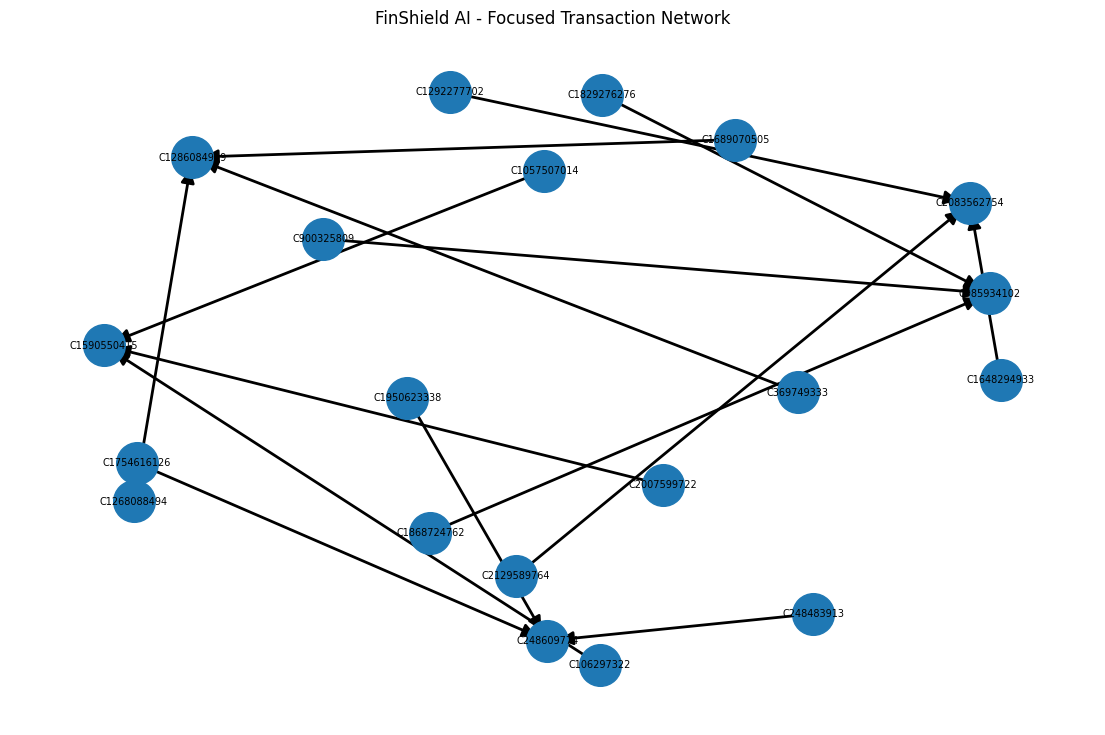

In [179]:
import matplotlib.pyplot as plt

import networkx as nx

# Выбираем 5 получателей с наибольшим количеством отправителей

top_accounts = network_results.head(5)["account_id"].tolist()

# Оставляем только 3 наиболее крупных отправителя для каждого получателя

selected_edges = []

for account in top_accounts:

    senders = list(transaction_graph.in_edges(account, data=True))

    senders = sorted(

        senders,

        key=lambda edge: edge[2]["total_amount"],

        reverse=True

    )[:3]

    selected_edges.extend(senders)

# Создаём компактный граф

small_graph = nx.DiGraph()

for sender, receiver, data in selected_edges:

    small_graph.add_edge(sender, receiver, **data)

plt.figure(figsize=(14, 9))

positions = nx.spring_layout(

    small_graph,

    seed=42,

    k=1.5

)

nx.draw_networkx_nodes(

    small_graph,

    positions,

    node_size=900

)

nx.draw_networkx_edges(

    small_graph,

    positions,

    arrows=True,

    arrowsize=20,

    width=2

)

nx.draw_networkx_labels(

    small_graph,

    positions,

    font_size=7

)

plt.title("FinShield AI - Focused Transaction Network")

plt.axis("off")

plt.show()

In [180]:
!pip install groq

In [181]:
from google.colab import userdata

api_key = userdata.get("GROQ_API_KEY")

print("API key connected:", api_key is not None)

API key connected: True


In [182]:
from groq import Groq

from google.colab import userdata

groq_client = Groq(

    api_key=userdata.get("GROQ_API_KEY")

)

print("Groq connected!")

Groq connected!


In [183]:
from groq import Groq

from google.colab import userdata

groq_client = Groq(

    api_key=userdata.get("GROQ_API_KEY")

)

response = groq_client.chat.completions.create(

    model="openai/gpt-oss-20b",

    messages=[

        {

            "role": "user",

            "content": "Reply with one word: READY"

        }

    ],

    max_completion_tokens=50

)

print(response.choices[0].message.content)

In [184]:
import json

def analyze_network_with_groq(network_summary):

    prompt = f"""

    You are a financial crime investigation analyst.

    Analyze the following transaction network data.

    DATA:

    {json.dumps(network_summary, indent=2)}

    Write a concise investigation report with these sections:

    1. Network Overview

    2. Suspicious Patterns

    3. Accounts Requiring Further Investigation

    4. Evidence

    5. Risk Assessment

    Rules:

    - Use only the supplied data.

    - Explain why each pattern may be suspicious.

    - Do not invent account details or transactions.

    - High connection counts do not prove fraud.

    - Keep the report under 400 words.

    """

    response = groq_client.chat.completions.create(

        model="openai/gpt-oss-20b",

        messages=[

            {

                "role": "system",

                "content": "You are a careful financial investigation analyst."

            },

            {

                "role": "user",

                "content": prompt

            }

        ],

        temperature=0.3,

        max_completion_tokens=1500

    )

    return response.choices[0].message.content

In [185]:
network_report = analyze_network_with_groq(network_summary)

print(network_report)

**Investigation Report – Transaction Network Snapshot**

**1. Network Overview**  
The dataset covers 151 551 accounts linked by 100 000 connections, generating a total transaction volume of $17.36 billion. The network is sparse relative to the number of accounts, suggesting a few highly active nodes. Two distinct groups emerge:  
- **High‑incoming nodes** (10 accounts) with 57–78 inbound links and no outbound activity, each receiving between $13 M and $34 M.  
- **High‑outgoing nodes** (10 accounts) with a single outbound link and no inbound activity, each sending between $145 and $125 k.

**2. Suspicious Patterns**  
- **Sink Accounts**: The high‑incoming nodes receive large sums yet never forward funds. This “receive‑only” pattern is characteristic of money‑laundering layering or funneling, where illicit proceeds are consolidated before further processing.  
- **Source‑Only Accounts**: The high‑outgoing nodes send money but receive none, implying they may be the initial distribution

In [186]:
print("NETWORK SUMMARY CHECK")

print("Total accounts:", network_summary["total_accounts"])

print("Total connections:", network_summary["total_connections"])

print("\nIncoming accounts:")

display(

    pd.DataFrame(

        network_summary["highest_incoming_connections"]

    )

)

print("\nOutgoing accounts:")

display(

    pd.DataFrame(

        network_summary["highest_outgoing_connections"]

    )

)

NETWORK SUMMARY CHECK
Total accounts: 151551
Total connections: 100000

Incoming accounts:


,account_id,incoming_connections,outgoing_connections,total_received,total_sent
0,C985934102,78,0,27870497.48,0.0
1,C1286084959,72,0,25203452.55,0.0
2,C248609774,71,0,33456497.77,0.0
3,C1590550415,69,0,34553165.77,0.0
4,C2083562754,66,0,28794765.39,0.0
5,C665576141,65,0,31574630.74,0.0
6,C977993101,65,0,13113125.87,0.0
7,C1360767589,62,0,27269481.54,0.0
8,C451111351,60,0,24712975.86,0.0
9,C1023714065,57,0,20480556.72,0.0



Outgoing accounts:


,account_id,incoming_connections,outgoing_connections,total_received,total_sent
0,C1000079132,0,1,0.0,2955.97
1,C1000109302,0,1,0.0,36834.52
2,C1000119377,0,1,0.0,144.56
3,C1000148923,0,1,0.0,124952.20
4,C99951544,0,1,0.0,5757.41
5,C999561483,0,1,0.0,7933.27
6,C999574557,0,1,0.0,10252.61
7,C999577303,0,1,0.0,17146.92
8,C999925989,0,1,0.0,19809.77
9,C1000039823,0,1,0.0,7781.12


In [187]:
def run_full_network_investigation():

    print("Network analysis started")

    report = analyze_network_with_groq(network_summary)

    print("Network analysis finished")

    return report

In [188]:
# Calculate top accounts by incoming connections

high_incoming = network_results.sort_values(

    "incoming_connections",

    ascending=False

).head(10)

# Calculate top accounts by outgoing connections

high_outgoing = network_results.sort_values(

    "outgoing_connections",

    ascending=False

).head(10)

# Create updated network summary

network_summary = {

    "total_accounts": int(transaction_graph.number_of_nodes()),

    "total_connections": int(transaction_graph.number_of_edges()),

    "total_transaction_amount": float(

        sum(

            data["total_amount"]

            for _, _, data in transaction_graph.edges(data=True)

        )

    ),

    "highest_incoming_connections": high_incoming.to_dict(

        orient="records"

    ),

    "highest_outgoing_connections": high_outgoing.to_dict(

        orient="records"

    )

}

print("NETWORK SUMMARY UPDATED!")

print("\nIncoming accounts:")

display(pd.DataFrame(network_summary["highest_incoming_connections"]))

print("\nOutgoing accounts:")

display(pd.DataFrame(network_summary["highest_outgoing_connections"]))

NETWORK SUMMARY UPDATED!

Incoming accounts:


,account_id,incoming_connections,outgoing_connections,total_received,total_sent
0,C985934102,78,0,27870497.48,0.0
1,C1286084959,72,0,25203452.55,0.0
2,C248609774,71,0,33456497.77,0.0
3,C1590550415,69,0,34553165.77,0.0
4,C2083562754,66,0,28794765.39,0.0
5,C665576141,65,0,31574630.74,0.0
6,C977993101,65,0,13113125.87,0.0
7,C1360767589,62,0,27269481.54,0.0
8,C451111351,60,0,24712975.86,0.0
9,C1023714065,57,0,20480556.72,0.0



Outgoing accounts:


,account_id,incoming_connections,outgoing_connections,total_received,total_sent
0,C1000079132,0,1,0.0,2955.97
1,C1000109302,0,1,0.0,36834.52
2,C1000119377,0,1,0.0,144.56
3,C1000148923,0,1,0.0,124952.20
4,C99951544,0,1,0.0,5757.41
5,C999561483,0,1,0.0,7933.27
6,C999574557,0,1,0.0,10252.61
7,C999577303,0,1,0.0,17146.92
8,C999925989,0,1,0.0,19809.77
9,C1000039823,0,1,0.0,7781.12


In [189]:
# 1. Select transfer transactions

transfers = investigation_df[

    investigation_df["type"] == "TRANSFER"

].copy()

# 2. Analyze recipients

recipient_analysis = transfers.groupby("nameDest").agg(

    transaction_count=("nameOrig", "count"),

    unique_senders=("nameOrig", "nunique"),

    total_received=("amount", "sum")

).reset_index()

# 3. Analyze senders

sender_analysis = transfers.groupby("nameOrig").agg(

    transaction_count=("nameDest", "count"),

    unique_receivers=("nameDest", "nunique"),

    total_sent=("amount", "sum")

).reset_index()

# 4. Display recipients receiving money

# from many different senders

print("TOP RECIPIENTS WITH MANY SENDERS")

display(

    recipient_analysis

    .sort_values("unique_senders", ascending=False)

    .head(10)

)

# 5. Display senders making many transfers

print("TOP SENDERS WITH MANY TRANSFERS")

display(

    sender_analysis

    .sort_values("transaction_count", ascending=False)

    .head(10)

)

TOP RECIPIENTS WITH MANY SENDERS


,nameDest,transaction_count,unique_senders,total_received
2547,C248609774,21,21,22620781.13
789,C1360767589,20,20,19461550.23
3423,C665576141,18,18,19494861.31
621,C1286084959,18,18,12650948.18
4135,C985934102,18,18,13011881.78
4106,C97730845,17,17,22833733.69
2669,C306206744,17,17,10938142.81
1280,C1590550415,17,17,22983127.33
3748,C803116137,17,17,18642155.01
3535,C716083600,16,16,18130290.81


TOP SENDERS WITH MANY TRANSFERS


,nameOrig,transaction_count,unique_receivers,total_sent
0,C1000109302,1,1,36834.52
1,C1000231597,1,1,1361999.80
2,C1000373644,1,1,626539.45
3,C1000411454,1,1,27540.67
4,C1000719581,1,1,1280020.98
5,C1000740725,1,1,467777.83
6,C1000839468,1,1,2485895.39
7,C1001304973,1,1,168393.30
8,C1001415350,1,1,573978.85
9,C1001704228,1,1,1250225.15


In [190]:
def investigate_recipient(recipient_id):

    # Find all transfers to this recipient

    transactions = transfers[

        transfers["nameDest"] == recipient_id

    ]

    if transactions.empty:

        return "No transactions found for this recipient."

    # Calculate investigation statistics

    senders = transactions["nameOrig"].nunique()

    transaction_count = len(transactions)

    total_received = transactions["amount"].sum()

    average_amount = transactions["amount"].mean()

    report = []

    report.append("FINSHIELD AI — FRAUD INVESTIGATION")

    report.append("----------------------------------")

    report.append(f"Recipient ID: {recipient_id}")

    report.append(f"Total transactions: {transaction_count}")

    report.append(f"Unique senders: {senders}")

    report.append(f"Total received: {total_received:,.2f}")

    report.append(f"Average transaction: {average_amount:,.2f}")

    report.append("\nINVESTIGATION FINDINGS:")

    if senders >= 5:

        report.append(

            "- Multiple different senders transferred money "

            "to this recipient."

        )

    if transaction_count >= 10:

        report.append(

            "- The recipient received a relatively large "

            "number of transfers."

        )

    if total_received > 1000000:

        report.append(

            "- The total received amount exceeds 1,000,000."

        )

    if senders < 5 and transaction_count < 10:

        report.append(

            "- No unusual activity detected by these basic rules."

        )

    report.append(

        "\nNote: These patterns are investigation signals, "

        "not proof of fraud."

    )

    return "\n".join(report)

In [191]:
recipient_id = recipient_analysis.sort_values(

    "unique_senders",

    ascending=False

).iloc[0]["nameDest"]

print(investigate_recipient(recipient_id))

FINSHIELD AI — FRAUD INVESTIGATION
----------------------------------
Recipient ID: C248609774
Total transactions: 21
Unique senders: 21
Total received: 22,620,781.13
Average transaction: 1,077,180.05

INVESTIGATION FINDINGS:
- Multiple different senders transferred money to this recipient.
- The recipient received a relatively large number of transfers.
- The total received amount exceeds 1,000,000.

Note: These patterns are investigation signals, not proof of fraud.


In [192]:
# Prepare recipient choices for the interface

recipient_choices = recipient_analysis.sort_values(

    "unique_senders",

    ascending=False

)["nameDest"].head(100).tolist()

print("Recipients available:", len(recipient_choices))

print("First 5 recipients:", recipient_choices[:5])

Recipients available: 100
First 5 recipients: ['C248609774', 'C1360767589', 'C665576141', 'C1286084959', 'C985934102']


In [193]:
import json

def generate_scenario(difficulty):

    prompt = f"""

    You are an expert financial fraud awareness educator.

    Create one realistic financial fraud scenario.

    Difficulty: {difficulty}

    Return ONLY valid JSON with exactly these 10 fields:

    {{

        "title": "Scenario title",

        "category": "Fraud category",

        "difficulty": "{difficulty}",

        "message_type": "SMS, Email, Phone call or Social media",

        "message": "A realistic suspicious message",

        "warning_signs": [

            "Warning sign 1",

            "Warning sign 2",

            "Warning sign 3",

            "Warning sign 4"

        ],

        "question": "What should the user do?",

        "options": [

            "Option 1",

            "Option 2",

            "Option 3"

        ],

        "correct": "The exact text of the safest option",

        "explanation": "Explain why this option is safest"

    }}

    Requirements:

    - Include exactly 4 warning signs.

    - Include exactly 3 answer options.

    - Make only one option the safest.

    - The correct field must exactly match one option.

    - Make the scenario realistic and educational.

    - Do not include real personal information.

    """

    response = groq_client.chat.completions.create(

        model="openai/gpt-oss-20b",

        messages=[

            {

                "role": "system",

                "content": "You generate realistic financial fraud awareness scenarios. Return valid JSON only."

            },

            {

                "role": "user",

                "content": prompt

            }

        ],

        temperature=0.7,

        max_completion_tokens=1500,

        response_format={"type": "json_object"}

    )

    scenario = json.loads(

        response.choices[0].message.content

    )

    required_fields = [

        "title", "category", "difficulty", "message_type",

        "message", "warning_signs", "question", "options",

        "correct", "explanation"

    ]

    for field in required_fields:

        if field not in scenario:

            raise ValueError(f"Missing field: {field}")

    if len(scenario["warning_signs"]) != 4:

        raise ValueError("Scenario must contain exactly 4 warning signs.")

    if len(scenario["options"]) != 3:

        raise ValueError("Scenario must contain exactly 3 options.")

    if scenario["correct"] not in scenario["options"]:

        raise ValueError("Correct answer must match one of the options.")

    return scenario

In [194]:
test_scenario = generate_scenario("Medium")

print(json.dumps(test_scenario, indent=4, ensure_ascii=False))

{
    "title": "Unexpected Bank Account Verification Request",
    "category": "Phishing",
    "difficulty": "Medium",
    "message_type": "SMS",
    "message": "Hi, this is your bank. Please confirm your account details to avoid suspension: 123-456-7890. Reply YES to proceed.",
    "warning_signs": [
        "Urgent request to provide personal info",
        "Unknown sender or phone number",
        "Request to reply with personal info",
        "No official branding or email address"
    ],
    "question": "What should the user do?",
    "options": [
        "Reply with requested info to avoid suspension",
        "Call the number shown in the message",
        "Ignore the message and log into your official bank app to verify"
    ],
    "correct": "Ignore the message and log into your official bank app to verify",
    "explanation": "Legitimate banks never ask for sensitive information via SMS or unsolicited calls. The safest action is to ignore the message and verify your account s

In [196]:
import json

try:

    parsed_scenario = json.loads(response.text)

    print("JSON IS VALID!")

    print("Fields:", list(parsed_scenario.keys()))

    print("Warning signs:", len(parsed_scenario["warning_signs"]))

    print("Options:", len(parsed_scenario["options"]))

except Exception as error:

    print("JSON ERROR:", error)

    print("RAW RESPONSE:")

    print(response)

JSON ERROR: 'ChatCompletion' object has no attribute 'text'
RAW RESPONSE:
ChatCompletion(id='chatcmpl-72ff42d1-0fa9-40c9-a390-a7ab0f0b2cea', choices=[Choice(finish_reason='length', index=0, logprobs=None, message=ChatCompletionMessage(content='', role='assistant', annotations=None, executed_tools=None, function_call=None, reasoning='The user says "Reply with one word: READY". That seems like an instruction: reply with one word: READY. That is, the assistant should reply with the word "READY". So output "READY".', tool_calls=None))], created=1794759733, model='openai/gpt-oss-20b', object='chat.completion', mcp_list_tools=None, service_tier='on_demand', system_fingerprint='fp_a8c584dda7', usage=CompletionUsage(completion_tokens=50, prompt_tokens=77, total_tokens=127, completion_time=0.051072985, completion_tokens_details=CompletionTokensDetails(reasoning_tokens=43), prompt_time=0.004400647, prompt_tokens_details=None, queue_time=0.151616051, total_time=0.055473632), usage_breakdown=None,

In [197]:
import random

import gradio as gr

def create_new_simulator_scenario(difficulty):

    scenario = generate_scenario(difficulty)

    message_display = (

        f"### {scenario['message_type']}\n\n"

        f"{scenario['message']}\n\n"

        f"**Question:** {scenario['question']}"

    )

    return (

        message_display,

        gr.update(

            choices=scenario["warning_signs"],

            value=[]

        ),

        gr.update(

            choices=scenario["options"],

            value=None

        ),

        "",

        scenario

    )

def check_generated_scenario(

    selected_signs,

    selected_option,

    scenario

):

    if scenario is None:

        return "Please generate a scenario first."

    if not selected_signs or selected_option is None:

        return "Identify warning signs and choose a response."

    correct_signs = scenario["warning_signs"]

    found = len(set(selected_signs) & set(correct_signs))

    total = len(correct_signs)

    strategy_correct = selected_option == scenario["correct"]

    score = round((found / total) * 50)

    if strategy_correct:

        score += 50

    result = [

        f"YOUR SCORE: {score}/100",

        f"Warning signs identified: {found}/{total}",

        "",

        "PROTECTION STRATEGY: " +

        ("Correct!" if strategy_correct else "Incorrect."),

        "",

        "EXPLANATION:",

        scenario["explanation"],

        "",

        "WARNING SIGNS:"

    ]

    for sign in correct_signs:

        if sign in selected_signs:

            result.append("[Identified] " + sign)

        else:

            result.append("[Missed] " + sign)

    return "\n".join(result)

print("FinShield AI simulator functions are ready!")

FinShield AI simulator functions are ready!


In [198]:
# ============================================================

# NETWORK REPORT CALLBACK

# ============================================================

def run_full_network_investigation():

    print("Network analysis started")

    report = analyze_network_with_groq(network_summary)

    print("Network analysis finished")

    return report

# ============================================================

# FINSHIELD AI - GRADIO INTERFACE

# ============================================================

with gr.Blocks(

    title="FinShield AI",

    theme=gr.themes.Soft()

) as finshield_app:

    gr.Markdown("# 🛡️ FinShield AI")

    gr.Markdown(

        "AI-powered financial fraud detection, investigation, "

        "and awareness platform."

    )

    # ========================================================

    # TAB 1: FRAUD DETECTION

    # ========================================================

    with gr.Tab("Fraud Detection"):

        gr.Markdown("## 🔍 Transaction Fraud Detection")

        gr.Markdown(

            "Enter transaction details to evaluate its fraud risk."

        )

        step_input = gr.Number(

            label="Transaction Step",

            value=1

        )

        type_input = gr.Dropdown(

            choices=[

                "PAYMENT",

                "TRANSFER",

                "CASH_OUT",

                "DEBIT",

                "CASH_IN"

            ],

            label="Transaction Type",

            value="TRANSFER"

        )

        amount_input = gr.Number(

            label="Transaction Amount",

            value=10000

        )

        old_balance_input = gr.Number(

            label="Sender Old Balance",

            value=20000

        )

        new_balance_input = gr.Number(

            label="Sender New Balance",

            value=10000

        )

        receiver_old_balance_input = gr.Number(

            label="Receiver Old Balance",

            value=5000

        )

        receiver_new_balance_input = gr.Number(

            label="Receiver New Balance",

            value=15000

        )

        detect_button = gr.Button(

            "Analyze Transaction",

            variant="primary"

        )

        detection_result = gr.Textbox(

            label="Fraud Detection Result",

            lines=4

        )

        detection_explanation = gr.Textbox(

            label="AI Explanation",

            lines=8

        )

        detect_button.click(

            fn=analyze_finshield,

            inputs=[

                step_input,

                type_input,

                amount_input,

                old_balance_input,

                new_balance_input,

                receiver_old_balance_input,

                receiver_new_balance_input

            ],

            outputs=[

                detection_result,

                detection_explanation

            ]

        )

    # ========================================================

    # TAB 2: FRAUD INVESTIGATION

    # ========================================================

    with gr.Tab("Fraud Investigation"):

        # INDIVIDUAL ACCOUNT INVESTIGATION

        gr.Markdown("## 🕵️ Individual Account Investigation")

        gr.Markdown(

            "Analyze transaction patterns associated with one account."

        )

        recipient_dropdown = gr.Dropdown(

            choices=recipient_choices,

            label="Select Recipient ID",

            interactive=True

        )

        investigate_button = gr.Button(

            "Investigate Account",

            variant="primary"

        )

        investigation_result = gr.Textbox(

            label="Individual Investigation Report",

            lines=12

        )

        investigate_button.click(

            fn=investigate_recipient,

            inputs=[recipient_dropdown],

            outputs=investigation_result

        )

        gr.Markdown("---")

        # ENTIRE NETWORK INVESTIGATION

        gr.Markdown("## 🌐 Entire Network Analysis")

        gr.Markdown(

            "Use Groq AI to analyze the overall transaction network "

            "and generate an investigation report."

        )

        network_button = gr.Button(

            "Analyze Entire Network",

            variant="primary"

        )

        network_report_output = gr.Markdown()

        network_button.click(

            fn=run_full_network_investigation,

            inputs=[],

            outputs=network_report_output

        )

    # ========================================================

    # TAB 3: FRAUD SIMULATOR

    # ========================================================

    with gr.Tab("Fraud Simulator"):

        gr.Markdown("## 🎯 Financial Fraud Awareness Simulator")

        gr.Markdown(

            "Practice recognizing suspicious financial situations "

            "through AI-generated scenarios."

        )

        current_scenario = gr.State(None)

        difficulty_dropdown = gr.Dropdown(

            choices=["Easy", "Medium", "Hard"],

            value="Medium",

            label="Choose Difficulty"

        )

        generate_button = gr.Button(

            "Generate New Scenario",

            variant="primary"

        )

        scenario_output = gr.Markdown(

            label="Fraud Scenario"

        )

        warning_signs_input = gr.CheckboxGroup(

            choices=[],

            label="Select the Warning Signs"

        )

        safest_option_input = gr.Radio(

            choices=[],

            label="What Would You Do?"

        )

        check_button = gr.Button(

            "Analyze My Answers",

            variant="primary"

        )

        simulator_result = gr.Markdown(

            label="Your Results"

        )

        generate_button.click(

            fn=create_new_simulator_scenario,

            inputs=[difficulty_dropdown],

            outputs=[

                scenario_output,

                warning_signs_input,

                safest_option_input,

                simulator_result,

                current_scenario

            ]

        )

        check_button.click(

            fn=check_generated_scenario,

            inputs=[

                warning_signs_input,

                safest_option_input,

                current_scenario

            ],

            outputs=simulator_result

        )

# ============================================================

# LAUNCH FINSHIELD AI

# ============================================================

finshield_app.launch(share=True)

/tmp/ipykernel_2236/255436574.py:23: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b357e8fec7d4a5d46a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
